# Assignment 4.1: Spatial Filtering: Correlation

### 1. Import Libraries


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### 2. Load and Display the Image


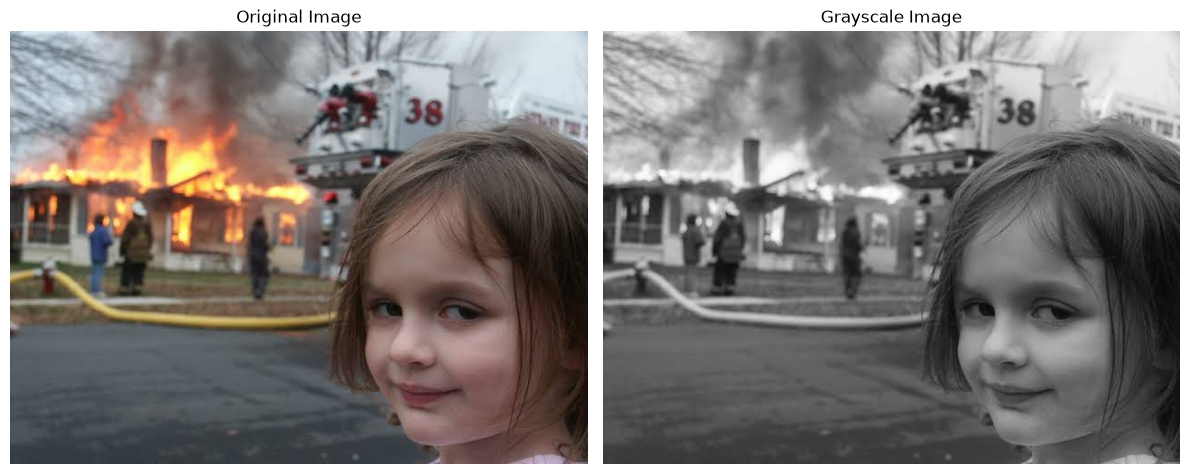

In [2]:
image_path = "../assets/input/sample.jpg"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

### 3. Define a Correlation Function


In [3]:
def spatial_correlation(image, kernel):
    image = image.astype(np.float32)
    kernel = np.asarray(kernel, dtype=np.float32)

    kernel_height, kernel_width = kernel.shape
    pad_height = kernel_height // 2
    pad_width = kernel_width // 2

    padded_image = np.pad(
        image,
        ((pad_height, pad_height), (pad_width, pad_width)),
        mode="constant",
        constant_values=0
    )

    output = np.zeros_like(image, dtype=np.float32)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            region = padded_image[
                i:i + kernel_height,
                j:j + kernel_width
            ]

            output[i, j] = np.sum(region * kernel)

    return output

### 4. Apply Correlation Using a 3×3 Kernel


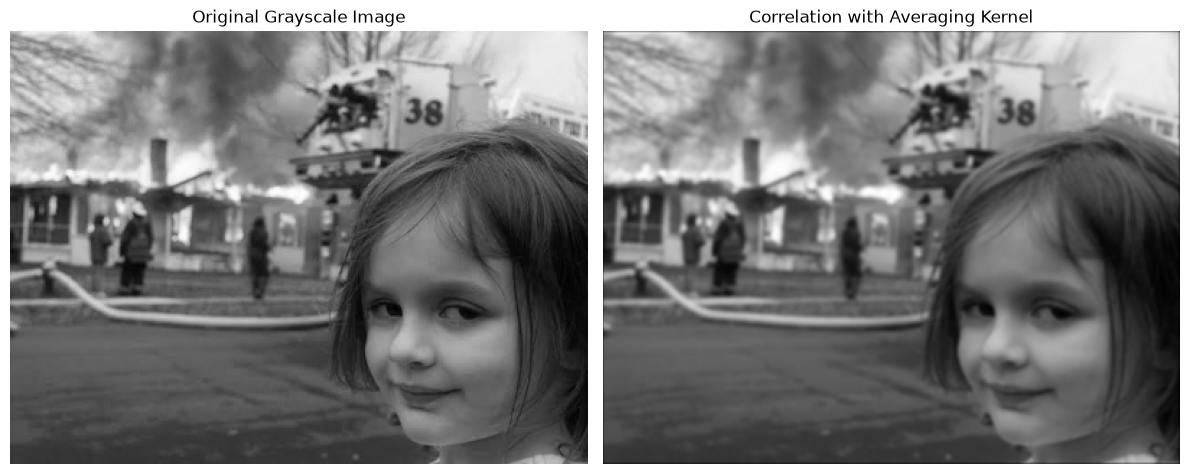

In [4]:
# Use a resized image for manual correlation to reduce execution time
small_image = cv2.resize(gray_image, (400, 300))

# Define a 3x3 averaging kernel
averaging_kernel = np.ones((3, 3), dtype=np.float32) / 9

# Perform spatial correlation
correlated_image = spatial_correlation(small_image, averaging_kernel)

# Clip values for display
correlated_display = np.clip(correlated_image, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(small_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(correlated_display, cmap="gray")
plt.title("Correlation with Averaging Kernel")
plt.axis("off")

plt.tight_layout()
plt.show()

### 5. Apply Different Correlation Kernels


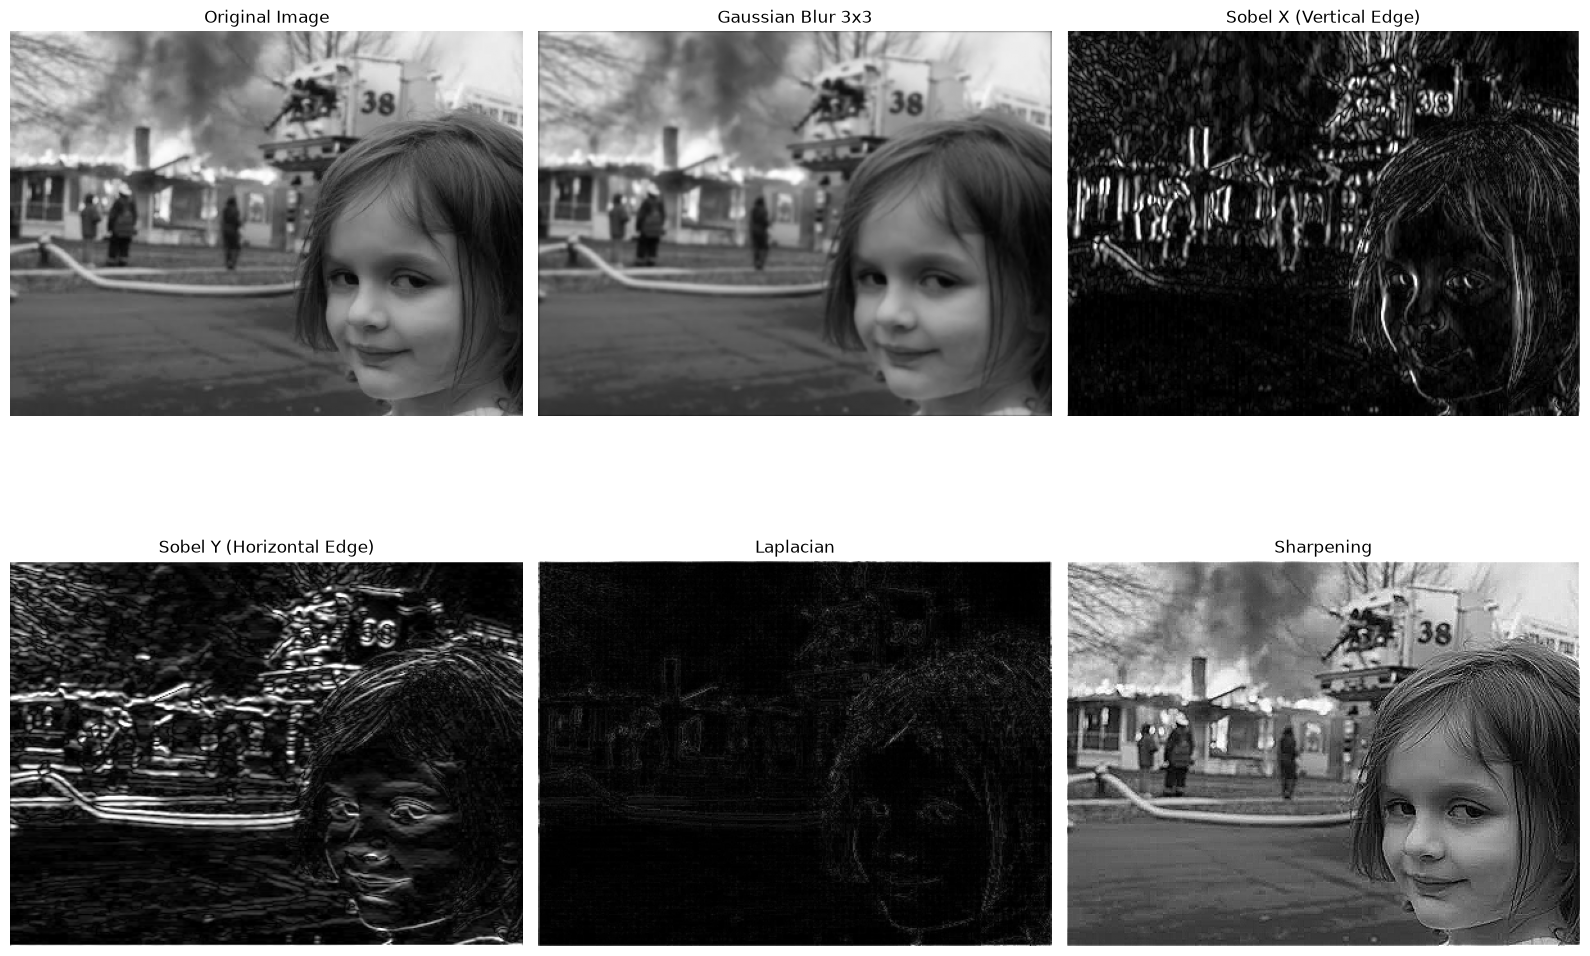

In [5]:
kernels = {
    "Gaussian Blur 3x3": np.array([
        [1, 2, 1],
        [2, 4, 2],
        [1, 2, 1]
    ], dtype=np.float32) / 16,

    "Sobel X (Vertical Edge)": np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ], dtype=np.float32),

    "Sobel Y (Horizontal Edge)": np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ], dtype=np.float32),

    "Laplacian": np.array([
        [0,  1, 0],
        [1, -4, 1],
        [0,  1, 0]
    ], dtype=np.float32),

    "Sharpening": np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ], dtype=np.float32)
}

plt.figure(figsize=(16, 12))

plt.subplot(2, 3, 1)
plt.imshow(small_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

for index, (name, kernel) in enumerate(kernels.items(), start=2):
    result = spatial_correlation(small_image, kernel)

    # Use absolute values for edge detection and Laplacian
    if "Sobel" in name or "Laplacian" in name:
        result = np.abs(result)

    result_display = np.clip(result, 0, 255).astype(np.uint8)

    plt.subplot(2, 3, index)
    plt.imshow(result_display, cmap="gray")
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

### 6. Display the Correlation Kernels


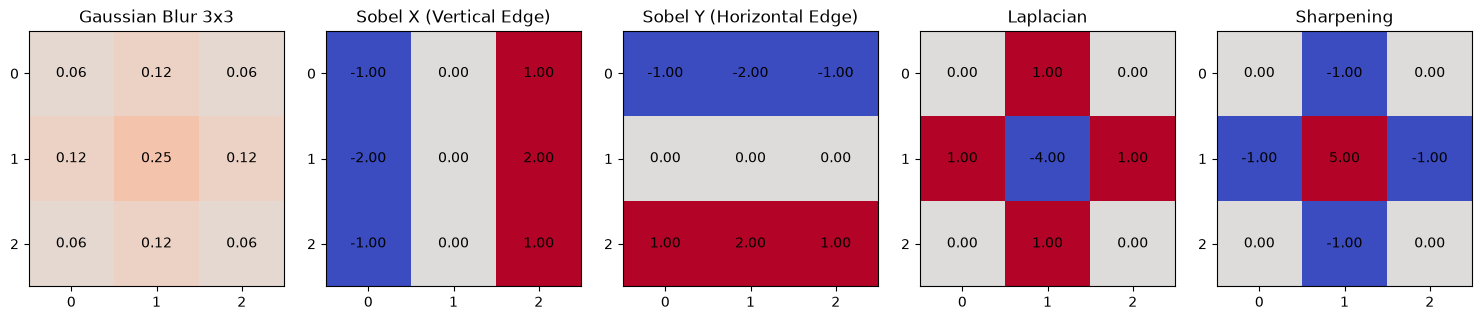

In [6]:
fig, axes = plt.subplots(1, len(kernels), figsize=(15, 3))

for ax, (name, kernel) in zip(axes, kernels.items()):
    ax.imshow(kernel, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_title(name)
    ax.set_xticks(range(kernel.shape[1]))
    ax.set_yticks(range(kernel.shape[0]))

    for i in range(kernel.shape[0]):
        for j in range(kernel.shape[1]):
            ax.text(j, i, f"{kernel[i, j]:.2f}",
                    ha="center", va="center", color="black")

plt.tight_layout()
plt.show()

### 7. Perform Correlation Using OpenCV


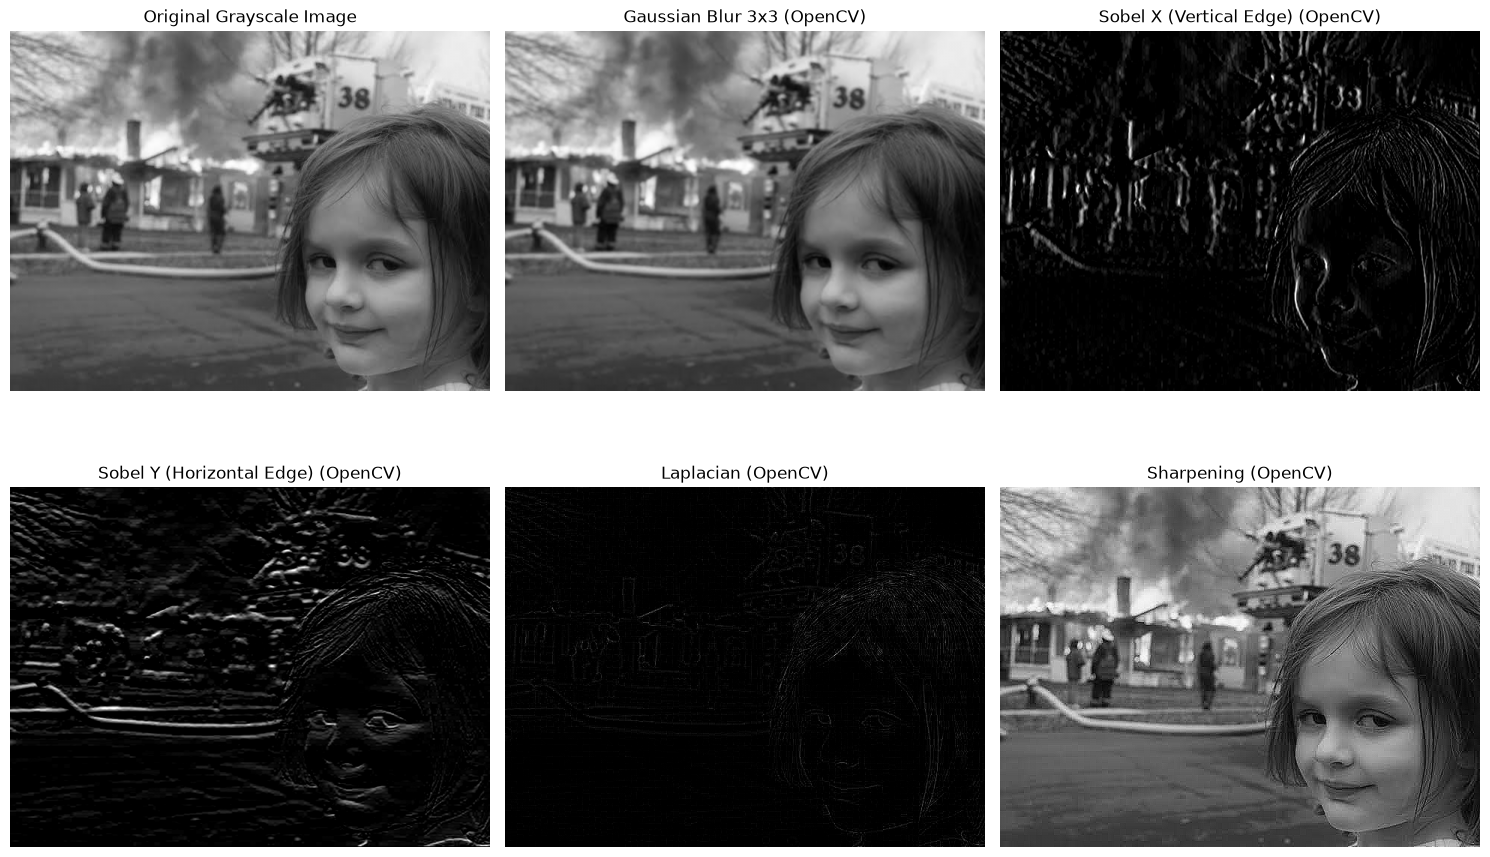

In [7]:
opencv_results = {}

for name, kernel in kernels.items():
    result = cv2.filter2D(
        gray_image,
        ddepth=cv2.CV_32F,
        kernel=kernel
    )

    opencv_results[name] = np.clip(result, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

for index, (name, result) in enumerate(opencv_results.items(), start=2):
    plt.subplot(2, 3, index)
    plt.imshow(result, cmap="gray")
    plt.title(f"{name} (OpenCV)")
    plt.axis("off")

plt.tight_layout()
plt.show()

### 8. Verify Correlation with an Example

In [8]:
sample_region = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
], dtype=np.float32)

test_kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
], dtype=np.float32)

correlation_value = np.sum(sample_region * test_kernel)

print("Sample Image Region:")
print(sample_region)

print("\nCorrelation Kernel:")
print(test_kernel)

print("\nCorrelation Value at the Center:", correlation_value)

Sample Image Region:
[[10. 20. 30.]
 [40. 50. 60.]
 [70. 80. 90.]]

Correlation Kernel:
[[ 1.  0. -1.]
 [ 1.  0. -1.]
 [ 1.  0. -1.]]

Correlation Value at the Center: -60.0
